# Food Freshness Classification with Deep Learning

Classifying **fresh vs. spoiled apples, oranges and tomatoes** (6 classes) using a self-collected image dataset.
The notebook walks through baselines (random guess, MLP, human-level performance), then improves the model step by step:
basic CNN → data augmentation → transfer learning (MobileNet) → MobileNet + augmentation → **EfficientNetB0 + augmentation (95% test accuracy)**, followed by error analysis.

## Create an Image Dataset

### A: Dataset Creation

-------------------------------------
### For my project, I needed pictures of food (oranges, apples, and tomatoes) to predict whether they were spoiled or not. To create my dataset, I used three sources. First, I tried Generative AI to create images, but most of them were not realistic, so I only used a few. Next, I attempted Web Scraping to collect images from websites, but I was able to find only a small number. Lastly, I found a free dataset on Kaggle, which provided a good number of images. To build a diverse dataset, I combined all these images from different sources, ensuring I had enough examples for both spoiled and fresh food items. In total, I collected 600 images — 100 for each class — to train and test my model.
-------------------------------------------

### B: Dataset Cleaning

----------------------------------------------------------------------------------------------------------------------------------------------------
### To make sure my dataset was good, I did a few things. First, I removed repeated images so there were no duplicates. Then, I deleted unrealistic images from Generative AI to keep the data real. After that, I sorted the images into two folders: spoiled and not spoiled, so they were easy to use. Finally, I checked for broken images and removed any that didn’t open. Additionally, I renamed my classes to follow a clear and structured format, ensuring that each image had a consistent and descriptive filename. I also converted all images to .jpg format to maintain consistency and avoid compatibility issues during model training.
--------------------------------------------------------------------

### C: Final Dataset

#### The dataset (600 images, 100 per class) is not included in this repository. To re-run the notebook, place the images in `data/Image_Dataset/<class name>/`.

### D: Load and Split

-------------------
#### Here, I loaded images from 6 classes: fresh and spoiled apples, oranges, and tomatoes. 
----------

In [1]:
import os
import numpy as np
import skimage.io as io
import skimage.transform as trans
import random
import tensorflow as tf
SEED = 42
np.random.seed(SEED)
random.seed(SEED)
tf.random.set_seed(SEED)

# # # Dataset folder
dataset_folder = "../data/Image_Dataset"

# # # Class names
class_names = ["Fresh Apples", "Spoiled Apples", "Fresh Oranges", "Spoiled Oranges", "Fresh Tomatoes", "Spoiled Tomatoes"]

target_size = (64,64)

X = []
y = []

for label, class_name in enumerate(class_names):
    folder_path = os.path.join(dataset_folder, class_name)  
    for filename in os.listdir(folder_path):
        image_path = os.path.join(folder_path, filename)
        image = io.imread(image_path) 
        
        image_resized = trans.resize(image, target_size, anti_aliasing=True, preserve_range=True)
        image_resized = image_resized.astype("uint8")  
        
        X.append(image_resized)  
        y.append(label)  

# # #  Convert lists to NumPy arrays
X = np.array(X)
y = np.array(y)

# # # Print dataset info
print(f"Total images loaded: {X.shape[0]}")
print(f"Image shape: {X.shape[1:]} ")
print("Sample raw pixel values:", X[0, 0, 0])  


Total images loaded: 600
Image shape: (64, 64, 3) 
Sample raw pixel values: [249 254 247]


In [2]:

from sklearn.model_selection import train_test_split

# # # First split: 80% Training, 20% Temp (which will be split into Validation and Test)
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.2, random_state=0, stratify=y)

# # # Second split: 50% of Temp to Validation, 50% to Test  10% each from original data
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=0, stratify=y_temp)

print(f"Training set: {X_train.shape[0]} images")
print(f"Validation set: {X_val.shape[0]} images")
print(f"Test set: {X_test.shape[0]} images")

Training set: 480 images
Validation set: 60 images
Test set: 60 images


## Calculate Baselines

### A: Random Guess Accuracy

---------------------------------------------------------------------------------------------------------------------------------------------------------------------------
#### I calculated the random guess accuracy by dividing 100 by the number of classes. Since my dataset has six classes (Fresh Apples, Spoiled Apples, Fresh Oranges, Spoiled Oranges, Fresh Tomatoes, and Spoiled Tomatoes), each class has the same chance of being picked randomly. Using the formula 100 ÷ 6 = 16.67%, this means if I guessed labels randomly, I would be right about 16.67% of the time.
---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

### B: Basic Multilayer Perceptron Accuracy

#### I: Preprocessing

------------
#### Here, I normalized my image data by dividing the pixel values by 255. This scales all pixel values to a range between 0 and 1,Next, I worked on preparing the labels for training. I used LabelEncoder to convert my class labels into numerical format, and then I used to_categorical to one-hot encode them.this is all i did for preprocessing.
------------------ 

In [3]:
import numpy as np

# # # Normalizing images 
X_train_mlp = X_train/255.0
X_val_mlp = X_val/255.0
X_test_mlp = X_test/255.0

print(f"Training data shape: {X_train_mlp.shape}")
print(f"Validation data shape: {X_val_mlp.shape}")
print(f"Test data shape: {X_test_mlp.shape}")
print("Sample pixel value:", X_train_mlp[5][2][6])

Training data shape: (480, 64, 64, 3)
Validation data shape: (60, 64, 64, 3)
Test data shape: (60, 64, 64, 3)
Sample pixel value: [0.9372549  0.94117647 0.94901961]


In [4]:

# # # Convert labels (Encode + One-hot in one step)
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.utils import to_categorical

label_encoder = LabelEncoder()
y_train_mlp = to_categorical(label_encoder.fit_transform(y_train))
y_val_mlp = to_categorical(label_encoder.transform(y_val))
y_test_mlp = to_categorical(label_encoder.transform(y_test))
 
print(f"Training labels shape: {y_train_mlp.shape}")
print(f"Validation labels shape: {y_val_mlp.shape}")
print(f"Test labels shape: {y_test_mlp.shape}")
print("Example labels:", y_train[:6])  
print("Encoded labels:", y_train_mlp[:6])  

Training labels shape: (480, 6)
Validation labels shape: (60, 6)
Test labels shape: (60, 6)
Example labels: [5 2 1 4 4 3]
Encoded labels: [[0. 0. 0. 0. 0. 1.]
 [0. 0. 1. 0. 0. 0.]
 [0. 1. 0. 0. 0. 0.]
 [0. 0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 1. 0.]
 [0. 0. 0. 1. 0. 0.]]


#### II: MLP Architecture 

In [5]:

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten,Dropout
from tensorflow.keras.optimizers import Adam

# # # Sequential model
mlp_model = Sequential()

# # #  Flatten the 64x64x3 images into 1D vectors
mlp_model.add(Flatten(input_shape=(64, 64, 3)))

# # # Hidden layers
mlp_model.add(Dense(64, activation='relu'))
mlp_model.add(Dense(128, activation='relu'))
# # #  Output layer 6 neurons (one for each class)
mlp_model.add(Dense(6, activation='softmax'))
# # # Compiling the model
mlp_model.compile(optimizer=Adam(learning_rate=0.001),loss='categorical_crossentropy',metrics=['accuracy'])
mlp_model.summary()


Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 flatten (Flatten)           (None, 12288)             0         
                                                                 
 dense (Dense)               (None, 64)                786496    
                                                                 
 dense_1 (Dense)             (None, 128)               8320      
                                                                 
 dense_2 (Dense)             (None, 6)                 774       
                                                                 
Total params: 795590 (3.03 MB)
Trainable params: 795590 (3.03 MB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


#### III: MLP Training

In [6]:
from tensorflow.keras.callbacks import EarlyStopping

# # #  early stopping callback
early_stopping = EarlyStopping( monitor="val_loss", patience=5,restore_best_weights=True)

# # #  Training the model with early stopping
H = mlp_model.fit(X_train_mlp, y_train_mlp, validation_data=(X_val_mlp, y_val_mlp),epochs=100,batch_size=32,callbacks=[early_stopping])

Epoch 1/100


15/15 [==============================] - 1s 21ms/step - loss: 2.0975 - accuracy: 0.2750 - val_loss: 1.5613 - val_accuracy: 0.4167
Epoch 2/100
15/15 [==============================] - 0s 8ms/step - loss: 1.4459 - accuracy: 0.3938 - val_loss: 1.2710 - val_accuracy: 0.5167
Epoch 3/100
15/15 [==============================] - 0s 8ms/step - loss: 1.2576 - accuracy: 0.4750 - val_loss: 1.2297 - val_accuracy: 0.4500
Epoch 4/100
15/15 [==============================] - 0s 8ms/step - loss: 1.2318 - accuracy: 0.5188 - val_loss: 1.1880 - val_accuracy: 0.5000
Epoch 5/100
15/15 [==============================] - 0s 8ms/step - loss: 1.2068 - accuracy: 0.5125 - val_loss: 1.1824 - val_accuracy: 0.5000
Epoch 6/100
15/15 [==============================] - 0s 8ms/step - loss: 1.1473 - accuracy: 0.5437 - val_loss: 1.0996 - val_accuracy: 0.5833
Epoch 7/100
15/15 [==============================] - 0s 8ms/step - loss: 1.1150 - accuracy: 0.5479 - val_loss: 1.0281 - val_accuracy: 0.6000
Epoch 8/10

#### IV: MLP Evaluation

In [7]:

# # # Evaluatting  the model on the test set
test_loss_mlp, test_accuracy_mlp = mlp_model.evaluate(X_test_mlp, y_test_mlp, verbose=1)
print(f"Test Loss: {test_loss_mlp:.4f}")
print(f"Test Accuracy: {test_accuracy_mlp:.4%}") 


2/2 [==============================] - 0s 3ms/step - loss: 1.0011 - accuracy: 0.7000
Test Loss: 1.0011
Test Accuracy: 70.0000%


# Learning Curves

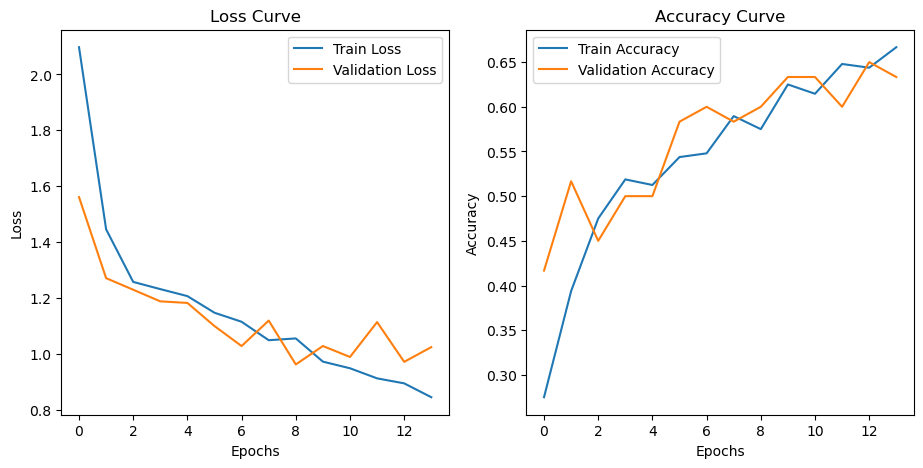

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 5))

# # # Loss Curve
plt.subplot(1, 2, 1)
plt.plot(H.history["loss"], label="Train Loss")
plt.plot(H.history["val_loss"], label="Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Loss Curve")
plt.legend()

# # # Accuracy Curve
plt.subplot(1, 2, 2)
plt.plot(H.history["accuracy"], label="Train Accuracy")
plt.plot(H.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Accuracy Curve")
plt.legend()

plt.show()

------
#### Here, I tested how different learning rates affect the performance of my MLP model.
----------------

In [9]:
# # #  testing with Diffrent learning rates
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

# --- Function to create the MLP model (no dropout) ---
def create_mlp_model():
    model = Sequential()
    model.add(Flatten(input_shape=(64, 64, 3)))
    model.add(Dense(64, activation='relu'))
    model.add(Dense(128, activation='relu'))
    model.add(Dense(6, activation='softmax')) 
    return model

learning_rates = [0.01, 0.001, 0.0001, 0.00001]  

results = {}

early_stopping = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
for lr in learning_rates:
    print(f"\nTraining with learning rate: {lr}")
    mlp_model = create_mlp_model()
    mlp_model.compile(optimizer=Adam(learning_rate=lr),loss='categorical_crossentropy',metrics=['accuracy'])
    history = mlp_model.fit( X_train_mlp, y_train_mlp,validation_data=(X_val_mlp, y_val_mlp),epochs=100,batch_size=32,callbacks=[early_stopping],verbose=0)
    test_loss, test_accuracy = mlp_model.evaluate(X_test_mlp, y_test_mlp, verbose=0)
    results[lr] = {"best_val_accuracy": max(history.history["val_accuracy"]),"final_test_accuracy": test_accuracy}

print("\n Final Results by Learning Rate:")
for lr, metrics in results.items():
    print(f"LR: {lr:<8} | Best Val Accuracy: {metrics['best_val_accuracy']:.4f} | Test Accuracy: {metrics['final_test_accuracy']:.4f}")
    


Training with learning rate: 0.01

Training with learning rate: 0.001

Training with learning rate: 0.0001

Training with learning rate: 1e-05

 Final Results by Learning Rate:
LR: 0.01     | Best Val Accuracy: 0.3833 | Test Accuracy: 0.3333
LR: 0.001    | Best Val Accuracy: 0.7500 | Test Accuracy: 0.7500
LR: 0.0001   | Best Val Accuracy: 0.7000 | Test Accuracy: 0.7500
LR: 1e-05    | Best Val Accuracy: 0.7333 | Test Accuracy: 0.7333



---------------
# Findings
#### LR = 0.01 : The learning rate was too high. The model was unstable and didn't learn well — accuracy fluctuated heavily.Best Validation Accuracy: 38.33% | Test Accuracy: 33.33%

#### LR = 0.001: This learning rate gave the best performance. Training was steady, and both validation and test results were high and consistent.Best Validation Accuracy: 75.00% | Test Accuracy: 75.00%

#### LR = 0.0001 : Also performed well, but slightly lower than 0.001. Training was stable but slower.Best Validation Accuracy: 70.00% | Test Accuracy: 75.00%

#### LR = 1e-5 : This rate trained very slowly. While it gave decent results, they were slightly below the best and not worth the extra time.Best Validation Accuracy: 73.33% | Test Accuracy: 73.33%
--------------------------------

-------------------
## Final Accuracy of the Basic MLP Model
#### After testing different learning rates and training the model for up to 100 epochs, the best validation accuracy reached 71.67%. When tested on new data, the model achieved a test accuracy of around 73%, showing good performance with some small changes between training runs. During training, the model's accuracy kept getting better. It started at 27.5% in Epoch 1 and reached about 66.7% by Epoch 14. Validation accuracy also improved, going from 41.7% to 65.0%. This shows the model was learning properly and generalizing well with each epoch.
----------------------------

### C: Human-Level Performance Accuracy

-----------
#### To estimate how well a human performs on this classification task, I created a Microsoft Forms https://forms.office.com/e/aggxpnz2mQ with 60 questions — 10 for each of the 6 classes (e.g., Fresh or Spoiled fruits). Each question showed one image and asked:“What is the class of this image?”
#### Three peers participated in the survey, and their scores were as follows: 90%, 95%, and 97%. To calculate the Human-Level Performance, I took the average of their scores:
#### Average Accuracy= 90 + 95 + 97/ 3 = 94% 
#### Final Human-Level Performance: 94%. This value serves as a benchmark to compare how well my model performs compared to a human.
#### <img src="../assets/human_level_survey.png" alt="Survey Screenshot" width="500"/>

---------------

## Basic Convolutional Neural Network (Iteration 1)

### A: Preprocessing

----------
#### I normalized my images by dividing pixel values by 255 to scale them between 0 and 1. I did this because when I trained the model without normalization, the learning was unstable and accuracy was low.I also used LabelEncoder and to_categorical to convert class labels into one-hot encoded format so the model could understand them. Additionally, I resized all images to 64x64 while loading the data. I tested different sizes and found that 64x64 gave the best balance between speed and accuracy for my model.
-------------

In [10]:
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.utils import to_categorical

# # # Normalizing images 
X_train_cnn1, X_val_cnn1, X_test_cnn1 = X_train / 255.0, X_val/ 255.0, X_test/ 255.0

# # #  Converting  (Encode + One-hot in one step)
label_encoder = LabelEncoder()
y_train_cnn1 = to_categorical(label_encoder.fit_transform(y_train))
y_val_cnn1 = to_categorical(label_encoder.transform(y_val))
y_test_cnn1 = to_categorical(label_encoder.transform(y_test))

# Printing the shape to check
print(f"Training data shape: {X_train_cnn1.shape}")
print(f"Validation data shape: {X_val_cnn1.shape}")
print(f"Test data shape: {X_test_cnn1.shape}")
print("Sample pixel value:", X_train_cnn1[5][0][0])
print("Example labels:", y_train[:6])  
print("Encoded labels:", y_train_cnn1[:6])  
print(f"Training labels shape: {y_train_cnn1.shape}")
print(f"Validation labels shape: {y_val_cnn1.shape}")
print(f"Test labels shape: {y_test_cnn1.shape}")

Training data shape: (480, 64, 64, 3)
Validation data shape: (60, 64, 64, 3)
Test data shape: (60, 64, 64, 3)
Sample pixel value: [0.93333333 0.9372549  0.95294118]
Example labels: [5 2 1 4 4 3]
Encoded labels: [[0. 0. 0. 0. 0. 1.]
 [0. 0. 1. 0. 0. 0.]
 [0. 1. 0. 0. 0. 0.]
 [0. 0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 1. 0.]
 [0. 0. 0. 1. 0. 0.]]
Training labels shape: (480, 6)
Validation labels shape: (60, 6)
Test labels shape: (60, 6)


### B: CNN Architecture

-------------
#### I started with two convolutional layers to help the model learn important features in the images, like shapes, colors, and edges. I tested different numbers of convolutional layers (like 1 or 3), but two layers gave the best balance between performance and training time. More layers didn’t improve accuracy and sometimes even made it worse.
#### After each convolutional layer, I added Batch Normalization to make training more stable and faster, and MaxPooling to reduce the size of the feature maps and focus on the most important details.
#### Then, I used Global Average Pooling instead of Flatten to reduce the number of parameters and prevent overfitting, especially since my dataset isn’t very large.I added Dense (fully connected) layers to help the model learn from the features and make final decisions. I also used Dropout to reduce overfitting by randomly turning off some neurons during training.Finally, I used a softmax output layer to classify the images into one of the 6 categories.
#### I also tried different learning rates and layer configurations, but this version gave the best results, so I kept it as my final model.
--------

In [11]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization,GlobalAveragePooling2D
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.backend import clear_session
clear_session()

# # #  the CNN model
cnn_model1 = Sequential()
# # # CNN Layer 1
cnn_model1.add(Conv2D(64, (3,3), activation='relu', input_shape=(64,64,3),padding='same'))
cnn_model1.add(BatchNormalization())
cnn_model1.add(MaxPooling2D(pool_size=(2,2)))

# # # CNN Layer 2
cnn_model1.add(Conv2D(128, (3,3), activation='relu',padding='same'))
cnn_model1.add(BatchNormalization())
cnn_model1.add(MaxPooling2D(pool_size=(2,2)))

# # # Flatten 
cnn_model1.add(GlobalAveragePooling2D())

# # #  Fully Connected Layers
cnn_model1.add(Dense(64, activation='relu'))
cnn_model1.add(Dense(128, activation='relu'))
cnn_model1.add(Dropout(0.5))
cnn_model1.add(Dense(6, activation='softmax')) 

# # # Compileing Model
cnn_model1.compile(optimizer=Adam(learning_rate=0.0001), loss='categorical_crossentropy',metrics=['accuracy'])
# # # # Model Summary
cnn_model1.summary()


Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 64, 64, 64)        1792      
                                                                 
 batch_normalization (Batch  (None, 64, 64, 64)        256       
 Normalization)                                                  
                                                                 
 max_pooling2d (MaxPooling2  (None, 32, 32, 64)        0         
 D)                                                              
                                                                 
 conv2d_1 (Conv2D)           (None, 32, 32, 128)       73856     
                                                                 
 batch_normalization_1 (Bat  (None, 32, 32, 128)       512       
 chNormalization)                                                
                                                       

### C: CNN Training

-----
#### I trained the CNN model by using the training images to help the model learn to tell the difference between the classes. I used a loss function called categorical crossentropy because there are six classes. I also used the Adam optimizer, which helps the model learn faster and better.I added EarlyStopping to stop training if the model stops getting better, so it doesn’t overfit.I used a batch size of 32 and trained the model for up to 100 epochs, but it usually stopped earlier.
--------------



In [12]:
from tensorflow.keras.callbacks import EarlyStopping

# EarlyStopping 
early_stopping = EarlyStopping(monitor="val_loss",patience=5,restore_best_weights=True)

# Training the CNN model
h_cnn1 =cnn_model1.fit(X_train_cnn1,y_train_cnn1,validation_data=(X_val_cnn1, y_val_cnn1),epochs=100,batch_size=32,callbacks=[early_stopping])


Epoch 1/100
15/15 [==============================] - 3s 116ms/step - loss: 1.7690 - accuracy: 0.2271 - val_loss: 1.7872 - val_accuracy: 0.1667
Epoch 2/100
15/15 [==============================] - 2s 108ms/step - loss: 1.6133 - accuracy: 0.3313 - val_loss: 1.7870 - val_accuracy: 0.1667
Epoch 3/100
15/15 [==============================] - 1s 93ms/step - loss: 1.5162 - accuracy: 0.4062 - val_loss: 1.7862 - val_accuracy: 0.2000
Epoch 4/100
15/15 [==============================] - 1s 90ms/step - loss: 1.4360 - accuracy: 0.4938 - val_loss: 1.7882 - val_accuracy: 0.2000
Epoch 5/100
15/15 [==============================] - 1s 89ms/step - loss: 1.3926 - accuracy: 0.4896 - val_loss: 1.7886 - val_accuracy: 0.1667
Epoch 6/100
15/15 [==============================] - 1s 90ms/step - loss: 1.3150 - accuracy: 0.5208 - val_loss: 1.7873 - val_accuracy: 0.1500
Epoch 7/100
15/15 [==============================] - 2s 107ms/step - loss: 1.2727 - accuracy: 0.5333 - val_loss: 1.7865 - val_accuracy: 0.1500
Epo

In [13]:
# # # Saving the model so i could use it for XAi using the other notebook
cnn_model1.save("../models/basic_cnn.h5")
np.save("../data/X_test_cnn.npy", X_test_cnn1)


c:\Users\nasra\anaconda3\envs\block_c\lib\site-packages\keras\src\engine\training.py:3103: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


## D: learning curves 

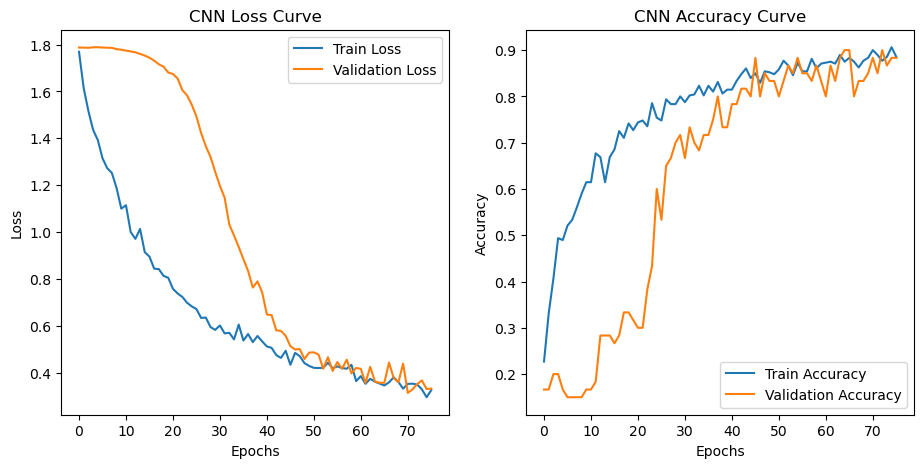

In [14]:
# # #  Plotting  training & validation loss and accuracy
import matplotlib.pyplot as plt
plt.figure(figsize=(11, 5))
# # # Loss Curve
plt.subplot(1, 2, 1)
plt.plot(h_cnn1.history["loss"], label="Train Loss")
plt.plot(h_cnn1.history["val_loss"], label="Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("CNN Loss Curve")
plt.legend()
# # #  Accuracy Curve
plt.subplot(1, 2, 2)
plt.plot(h_cnn1.history["accuracy"], label="Train Accuracy")
plt.plot(h_cnn1.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("CNN Accuracy Curve")
plt.legend()
plt.show()

--------
# Training Findings from the Curves
#### The graphs show that as training went on, the model’s loss kept going down while accuracy went up for both training and validation. This means the model was learning well. Around 70+ epochs, both curves became stable and close to each other, showing that the model didn’t overfit and can generalize well to new data.
------------

### E: Model Evaluation

-----------
#### To evaluate my CNN model, I used the test dataset, which the model hadn’t seen during training. I measured its performance using accuracy and loss. I also used a confusion matrix and calculated other metrics like precision, recall, and F1 score to better understand how well the model performed for each class.
--------------

In [15]:
# # #  Evaluating the CNN model on the test set
test_loss_itration1, test_accuracy_itration1 = cnn_model1.evaluate(X_test_cnn1, y_test_cnn1)

# # #  Print test loss and accuracy
print(f"Test Loss for CNN_1: {test_loss_itration1:.4f}")
print(f"Test Accuracy for CNN_1: {test_accuracy_itration1:.4%}")


2/2 [==============================] - 0s 27ms/step - loss: 0.4596 - accuracy: 0.8500
Test Loss for CNN_1: 0.4596
Test Accuracy for CNN_1: 85.0000%


### F : Confusion matrixes 

2/2 [==============================] - 0s 26ms/step


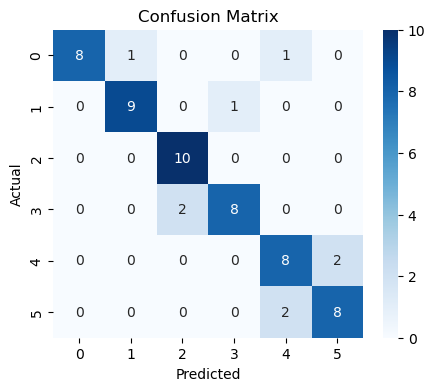

              precision    recall  f1-score   support

           0       1.00      0.80      0.89        10
           1       0.90      0.90      0.90        10
           2       0.83      1.00      0.91        10
           3       0.89      0.80      0.84        10
           4       0.73      0.80      0.76        10
           5       0.80      0.80      0.80        10

    accuracy                           0.85        60
   macro avg       0.86      0.85      0.85        60
weighted avg       0.86      0.85      0.85        60



In [16]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

y_pred = cnn_model1.predict(X_test_cnn1)
y_pred_classes = np.argmax(y_pred, axis=1)  
y_true = np.argmax(y_test_cnn1, axis=1)  

# # # Confusion Matrix
conf_matrix = confusion_matrix(y_true, y_pred_classes)

# # # Plotting Confusion Matrix
plt.figure(figsize=(5, 4))
sns.heatmap(conf_matrix, annot=True, cmap="Blues", fmt="d")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()
print(classification_report(y_true, y_pred_classes))


--------
#### The confusion matrix shows that the model correctly predicted most of the images for each class. For example, class 2 (Fresh Oranges) had all 10 correctly predicted, and class 1 (Spoiled Apples) had 9 correct and 1 slightly confused with a similar class.

#### The classification report also supports this. Most classes have high precision and recall values (around 0.80 to 1.00), showing that the model is reliable and not guessing randomly. The average F1-score was 0.85, meaning the model balances both precision and recall well.
#### The model did best on: Fresh Oranges (class 2) – 100% recall, no mistakes. Spoiled Apples (class 1) – 90% precision and recall.
#### The model struggled more with: Spoiled Tomatoes (class 5) and Fresh Tomatoes (class 4) where a few images were confused between them. This makes sense because those classes may look visually similar.
-----------------

-------------
# Results from My First CNN Model (Task 3.3)
#### My first CNN model gave good results. It reached 85% accuracy on the test set, which is much better than the MLP baseline that had 70% accuracy. This shows the CNN could learn important features from the images. The training and validation accuracy were also close, meaning the model didn’t overfit and learned well from the data.

#### During training, the model showed steady improvement. At the start (Epoch 1), training accuracy was only 22.7%, and validation accuracy was 16.7%. But as training continued, both improved a lot. By Epoch 30, the validation accuracy reached 71.67%. The training accuracy also kept improving, showing the model was learning important features from the images. The fact that validation accuracy stayed close to training accuracy means the model generalizes well and is not overfitting.
--------------

# Basic CNN1 (Task 3.3) Comparison with Baseline (Task 3.2)

| **Model** | **Description** | **Techniques Used** | **Test Accuracy** |
|-----------|-----------------|----------------------|-------------------|
| **MLP (Task 3.2)** | The MLP model was used as the starting point and got 70% accuracy on the test set. It worked okay, but it couldn’t understand the shapes and patterns in the images very well. | Fully connected layers only. | **70%** |
| **CNN1 (Task 3.3)** | The CNN1 model did much better, getting 85% test accuracy. This is because CNNs are better at finding features in images, like edges, colors, and textures.In short, CNN1 was more suitable for image tasks and gave much better results than the basic MLP model.. | Batch Normalization, MaxPooling, Dropout | **85%** |


## Data Augmentation (Iteration 2)

### A: Preprocessing

----
#### In this iteration, I reused the same normalization and label encoding steps from Iteration 1 just changed the names to prepare the dataset. But This time, I added data augmentation to make the model more robust by creating slightly different versions of the training images through random transformations like rotation, zoom, and flipping.
---------

In [17]:
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# # # Normalizing images 
X_train_cnn2, X_val_cnn2, X_test_cnn2 = X_train/ 255.0, X_val/ 255.0, X_test/ 255.0

# # #  Converting  (Encode + One-hot in one step)
label_encoder = LabelEncoder()
y_train_cnn2 = to_categorical(label_encoder.fit_transform(y_train))
y_val_cnn2 = to_categorical(label_encoder.transform(y_val))
y_test_cnn2 = to_categorical(label_encoder.transform(y_test))

# # # Applying augmentation ONLY to the training dataset
data_gen = ImageDataGenerator(rotation_range=5, width_shift_range=0.1,height_shift_range=0.1,shear_range=0.1,zoom_range=0.05,horizontal_flip=True,fill_mode='nearest')
X_train_augmented = data_gen.flow(X_train_cnn2, y_train_cnn2)

# Printing the shape to check
print(f"Training data shape: {X_train_cnn2.shape}")
print(f"Validation data shape: {X_val_cnn2.shape}")
print(f"Test data shape: {X_test_cnn2.shape}")
print("Sample pixel value:", X_train_cnn2[5][0][0])
print("Example labels:", y_train[:6])  
print("Encoded labels:", y_train_cnn2[:6])  
print(f"Training labels shape: {y_train_cnn2.shape}")
print(f"Validation labels shape: {y_val_cnn2.shape}")
print(f"Test labels shape: {y_test_cnn2.shape}")

Training data shape: (480, 64, 64, 3)
Validation data shape: (60, 64, 64, 3)
Test data shape: (60, 64, 64, 3)
Sample pixel value: [0.93333333 0.9372549  0.95294118]
Example labels: [5 2 1 4 4 3]
Encoded labels: [[0. 0. 0. 0. 0. 1.]
 [0. 0. 1. 0. 0. 0.]
 [0. 1. 0. 0. 0. 0.]
 [0. 0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 1. 0.]
 [0. 0. 0. 1. 0. 0.]]
Training labels shape: (480, 6)
Validation labels shape: (60, 6)
Test labels shape: (60, 6)


### B: CNN Architecture

-------
#### In this iteration, I used the same CNN architecture as Iteration 1 so I could fairly compare the models. The goal was to see how data augmentation affects performance when the architecture stays the same. I added augmentation to make the training data more diverse and realistic like what the model might see in real-world situations (eg, different angles, lighting, or positions). This helps the model generalize better and not just memorize the training data. I also tried changing the architecture, but the results stayed about the same, so I kept the original setup.
------------------

In [18]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Dense, Dropout, BatchNormalization,GlobalAveragePooling2D
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.backend import clear_session
clear_session()

# # # CNN Model (Same architecture as Iteration 1)
cnn_model2 = Sequential()

# # # CNN Layer 1 
cnn_model2.add(Conv2D(64, (3,3), activation='relu', input_shape=(64,64,3),padding='same'))
cnn_model2.add(BatchNormalization())
cnn_model2.add(MaxPooling2D(pool_size=(2,2)))

# # # CNN Layer 2
cnn_model2.add(Conv2D(128, (3,3), activation='relu',padding='same'))
cnn_model2.add(BatchNormalization())
cnn_model2.add(MaxPooling2D(pool_size=(2,2)))

# # # Flatten 
cnn_model2.add(GlobalAveragePooling2D())

# # #  Fully Connected Layers
cnn_model2.add(Dense(64, activation='relu'))
cnn_model2.add(Dense(128, activation='relu'))
cnn_model2.add(Dropout(0.5))
cnn_model2.add(Dense(6, activation='softmax')) 

# # # Compileing Model
cnn_model2.compile(optimizer=Adam(learning_rate=0.0001), loss='categorical_crossentropy',metrics=['accuracy'])
# # # # Model Summary
cnn_model2.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 64, 64, 64)        1792      
                                                                 
 batch_normalization (Batch  (None, 64, 64, 64)        256       
 Normalization)                                                  
                                                                 
 max_pooling2d (MaxPooling2  (None, 32, 32, 64)        0         
 D)                                                              
                                                                 
 conv2d_1 (Conv2D)           (None, 32, 32, 128)       73856     
                                                                 
 batch_normalization_1 (Bat  (None, 32, 32, 128)       512       
 chNormalization)                                                
                                                        

### C: CNN Training

--------
#### I trained the model using the same strategy as in Iteration 1, but this time I used augmented images for training. The learning rate, optimizer, and batch size were kept the same to focus on the impact of data augmentation.
-------------

In [19]:
from tensorflow.keras.callbacks import EarlyStopping

# # # EarlyStopping 
early_stopping = EarlyStopping(monitor="val_loss",patience=5,restore_best_weights=True)

# # # Training the CNN model
h_cnn2 =cnn_model2.fit(X_train_augmented,validation_data=(X_val_cnn2, y_val_cnn2),epochs=100,batch_size=32,callbacks=[early_stopping])

Epoch 1/100
15/15 [==============================] - 3s 125ms/step - loss: 1.7811 - accuracy: 0.2125 - val_loss: 1.7887 - val_accuracy: 0.1667
Epoch 2/100
15/15 [==============================] - 2s 108ms/step - loss: 1.6049 - accuracy: 0.3208 - val_loss: 1.7865 - val_accuracy: 0.3000
Epoch 3/100
15/15 [==============================] - 2s 115ms/step - loss: 1.5214 - accuracy: 0.4146 - val_loss: 1.7849 - val_accuracy: 0.2833
Epoch 4/100
15/15 [==============================] - 2s 116ms/step - loss: 1.4729 - accuracy: 0.4021 - val_loss: 1.7843 - val_accuracy: 0.2833
Epoch 5/100
15/15 [==============================] - 2s 108ms/step - loss: 1.3878 - accuracy: 0.4688 - val_loss: 1.7804 - val_accuracy: 0.3333
Epoch 6/100
15/15 [==============================] - 2s 109ms/step - loss: 1.3509 - accuracy: 0.5042 - val_loss: 1.7775 - val_accuracy: 0.2667
Epoch 7/100
15/15 [==============================] - 2s 115ms/step - loss: 1.3036 - accuracy: 0.5063 - val_loss: 1.7753 - val_accuracy: 0.1667

## D: learning curves 

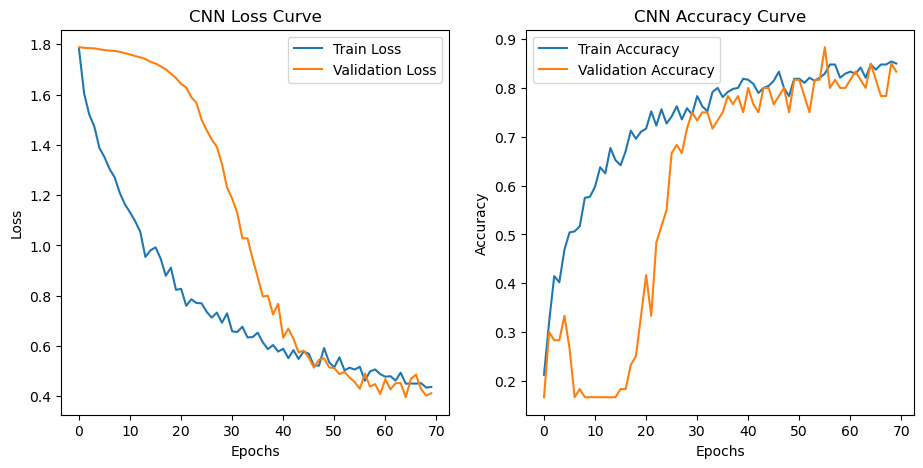

In [20]:
# # # Plotting training & validation loss and accuracy
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 5))
# # # Loss Curve
plt.subplot(1, 2, 1)
plt.plot(h_cnn2.history["loss"], label="Train Loss")
plt.plot(h_cnn2.history["val_loss"], label="Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("CNN Loss Curve")
plt.legend()
# # # Accuracy Curve
plt.subplot(1, 2, 2)
plt.plot(h_cnn2.history["accuracy"], label="Train Accuracy")
plt.plot(h_cnn2.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("CNN Accuracy Curve")
plt.legend()
# Show the plots
plt.show()

------
# Training Findings from the Curves
#### This graph shows that after adding data augmentation, the model learned steadily and improved well. In the loss curve, both training and validation loss decreased consistently, which means the model didn't overfit. The accuracy curve also shows that both training and validation accuracy went up together and stayed close, reaching around 85%, which means the model was able to generalize better
------------

### E: Model Evaluation

---------
#### I evaluated the model using the test dataset to see how well it performs on new images it hasn’t seen before. I used accuracy and loss as the main evaluation metrics. To understand if the model generalizes well and if data augmentation in this iteration improved the results compared to Iteration1 .
---------

In [21]:
# # #  Evaluating the CNN model on the test set
test_loss_itration2, test_accuracy_itration2 = cnn_model2.evaluate(X_test_cnn2, y_test_cnn2)

# # #  Print test loss and accuracy
print(f"Test Loss for CNN_V1: {test_loss_itration2:.4f}")
print(f"Test Accuracy for CNN_V1: {test_accuracy_itration2:.4%}")

2/2 [==============================] - 0s 29ms/step - loss: 0.4280 - accuracy: 0.8667
Test Loss for CNN_V1: 0.4280
Test Accuracy for CNN_V1: 86.6667%


### F : Confusion matrixes 

2/2 [==============================] - 0s 25ms/step


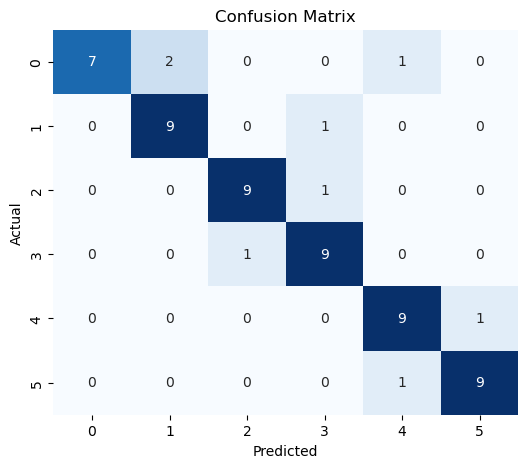

              precision    recall  f1-score   support

           0       1.00      0.70      0.82        10
           1       0.82      0.90      0.86        10
           2       0.90      0.90      0.90        10
           3       0.82      0.90      0.86        10
           4       0.82      0.90      0.86        10
           5       0.90      0.90      0.90        10

    accuracy                           0.87        60
   macro avg       0.88      0.87      0.87        60
weighted avg       0.88      0.87      0.87        60



In [22]:

# # # Importing necessary libraries
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# # # Predicting on the test set
y_pred = cnn_model2.predict(X_test_cnn2)
# # # Converting predictions to class labels
y_pred_classes = np.argmax(y_pred, axis=1)
# # # Ground truth values
y_true = np.argmax(y_test_cnn2, axis=1)
# # # Confusion Matrix
conf_matrix = confusion_matrix(y_true, y_pred_classes)
# # # Plotting Confusion Matrix
plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=True, cmap="Blues", fmt="d", cbar=False)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()
# # # Classification Report
print(classification_report(y_true, y_pred_classes))


--------
#### This confusion matrix and classification report show strong results after applying data augmentation. The overall accuracy is 87%, and most classes have high precision, recall, and F1-scores around 0.86–0.90. The model made a few mistakes, mostly confusing similar classes like class 0 (Fresh Apples) with class 1 (Spoiled Apples), but performance improved across the board compared to the previous iteration.
-----------------

--------
# Final results from My second CNN Model (Task 3.4)
#### The CNN model in this iteration achieved a test accuracy of around 86.67% and a test loss of 0.4280. Data augmentation was added to help the model generalize better. This time, the model slightly outperformed the previous iteration.
#### During training, the model’s accuracy improved steadily. It started at 21.25% in Epoch 1 and reached 85.00% by Epoch 70. Validation accuracy also increased, going from 16.67% to around 83.33%, showing the model was learning well and generalizing better with each epoch.
-----------------

## Basic CNN1 (Iteration 1) (Task 3.3) Comparison with Data Augmentation (Iteration 2) (Task 3.4)

| **Model Name**                      | **Accuracy** | **Loss** | **Explanation** |
|------------------------------------|--------------|----------|-----------------|
| Basic CNN1 (Iteration 1)           | 85.00%       | 0.4596   | In Iteration 1, the basic CNN model reached 85.00% test accuracy with a loss of 0.4596. |
| CNN2 with Data Augmentation (Iteration 2) | 86.67%       | 0.4280   | In Iteration 2, after adding data augmentation, the model slightly improved, reaching 86.67% test accuracy and a lower loss of 0.4280. However, the improvement was small, which means the original model already worked quite well. I also tried to redefine the CNN architecture and experiment with different layers, hyperparameters, and evaluation metrics to better handle the augmented data, but those changes actually made the results worse. When I removed augmentation and trained the model again, the results were very similar to Iteration 1. This suggests that the model might learn better from the original (non-augmented) data in this case, and data augmentation didn’t provide a clear benefit. |



## Transfer Learning (Iteration 3)

### A: Preprocessing

------------------
#### For this iteration, I resized all images to 224×224 to match MobileNet’s input size. Instead of dividing by 255, I used preprocess_input for proper normalization. I also used LabelEncoder and one-hot encoding for the labels—same as in previous iterations.
--------------------

In [23]:

from tensorflow.keras.utils import to_categorical
from sklearn.preprocessing import LabelEncoder
import tensorflow as tf
from tensorflow.keras.applications.mobilenet import preprocess_input

# # # Resizing images to 128x128 
X_train_cnn3 = tf.image.resize(X_train, (224,224))
X_val_cnn3 = tf.image.resize(X_val, (224, 224))
X_test_cnn3 = tf.image.resize(X_test, (224,224))

# # # Apply MobileNet preprocessing 
X_train_cnn3 = preprocess_input(X_train_cnn3)
X_val_cnn3 = preprocess_input(X_val_cnn3)
X_test_cnn3 = preprocess_input(X_test_cnn3)

# # # labels using LabelEncoder and convert to one-hot
label_encoder = LabelEncoder()
y_train_cnn3 = to_categorical(label_encoder.fit_transform(y_train))
y_val_cnn3 = to_categorical(label_encoder.transform(y_val))
y_test_cnn3 = to_categorical(label_encoder.transform(y_test))

print(f"Training data shape: {X_train_cnn3.shape}")
print(f"Validation data shape: {X_val_cnn3.shape}")
print(f"Test data shape: {X_test_cnn3.shape}")
print("Example encoded labels:", y_train_cnn3[:6])

Training data shape: (480, 224, 224, 3)
Validation data shape: (60, 224, 224, 3)
Test data shape: (60, 224, 224, 3)
Example encoded labels: [[0. 0. 0. 0. 0. 1.]
 [0. 0. 1. 0. 0. 0.]
 [0. 1. 0. 0. 0. 0.]
 [0. 0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 1. 0.]
 [0. 0. 0. 1. 0. 0.]]


### B: CNN Architecture

------------
#### In this iteration, I used a pre-trained MobileNet model because it’s efficient, performs well with limited data, and helped my model learn better through feature extraction and fine-tuning.to help my model learn better. At first, I froze the whole MobileNet part and only trained the new layers I added on top. This gave me about 88% accuracy.

#### Then, I changed my plan and unfroze the top 20 layers of MobileNet. This allowed the model to keep learning from my data while still using what it had already learned before. After this change, the model got around 93% accuracy.

#### So, my strategy was to use feature extraction and also fine-tune the top layers. This helped the model work better with my dataset.
---------------

In [24]:
from tensorflow.keras.applications import MobileNet
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.optimizers import Adam

# # # Loadding MobileNet Without Fully Connected Layers
base_model = MobileNet(include_top=False, weights='imagenet', input_shape=(224, 224, 3))

# # #  Freezing MobileNet's Convolutional Layers 
base_model.trainable = True

# Freeze all layers except the top 20
for layer in base_model.layers[:-20]:
    layer.trainable = False

# # # Adding Custom Classifier 
inputs = Input(shape=(224, 224, 3))
x = base_model(inputs, training=False)
x = GlobalAveragePooling2D()(x)

x = Dense(64, activation='relu')(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.5)(x)

# # # Outputs 6 classes 
outputs = Dense(6, activation='softmax')(x)

cnn_model3 = Model(inputs, outputs)
cnn_model3.compile(optimizer=Adam(learning_rate=0.0001),loss='categorical_crossentropy',metrics=['accuracy'])
cnn_model3.summary()

Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None, 224, 224, 3)]     0         
                                                                 
 mobilenet_1.00_224 (Functi  (None, 7, 7, 1024)        3228864   
 onal)                                                           
                                                                 
 global_average_pooling2d_1  (None, 1024)              0         
  (GlobalAveragePooling2D)                                       
                                                                 
 dense_3 (Dense)             (None, 64)                65600     
                                                                 
 dense_4 (Dense)             (None, 128)               8320      
                                                                 
 dropout_1 (Dropout)         (None, 128)               0     

### C: CNN Training

----------
#### To train the model, I used the Adam optimizer with a small learning rate (0.0001) and categorical cross-entropy as the loss function because I had 6 classes.I added EarlyStopping to stop training if the model stopped improving, so it doesn’t overfit. I used a batch size of 32, which worked well.I also tried different hyperparameter settings like other learning rates and batch sizes, but this setup gave me the best results.
----------------

In [25]:

from tensorflow.keras.callbacks import EarlyStopping

#  Early Stopping to Prevent Overfitting
early_stopping = EarlyStopping(monitor='val_loss',patience=5,restore_best_weights=True)

#  Train the Fully Connected Model
h_cnn3 = cnn_model3.fit( X_train_cnn3, y_train_cnn3,validation_data=(X_val_cnn3, y_val_cnn3),epochs=100,batch_size=32,callbacks=[early_stopping],verbose=1)

Epoch 1/100
15/15 [==============================] - 10s 428ms/step - loss: 1.6088 - accuracy: 0.3875 - val_loss: 1.0926 - val_accuracy: 0.6333
Epoch 2/100
15/15 [==============================] - 5s 350ms/step - loss: 1.1967 - accuracy: 0.5542 - val_loss: 0.8612 - val_accuracy: 0.7500
Epoch 3/100
15/15 [==============================] - 5s 359ms/step - loss: 0.9929 - accuracy: 0.6187 - val_loss: 0.6906 - val_accuracy: 0.7833
Epoch 4/100
15/15 [==============================] - 5s 357ms/step - loss: 0.9391 - accuracy: 0.6500 - val_loss: 0.5648 - val_accuracy: 0.8333
Epoch 5/100
15/15 [==============================] - 6s 377ms/step - loss: 0.7820 - accuracy: 0.7229 - val_loss: 0.5851 - val_accuracy: 0.7833
Epoch 6/100
15/15 [==============================] - 6s 410ms/step - loss: 0.6857 - accuracy: 0.7563 - val_loss: 0.3727 - val_accuracy: 0.9000
Epoch 7/100
15/15 [==============================] - 5s 359ms/step - loss: 0.5580 - accuracy: 0.8125 - val_loss: 0.3607 - val_accuracy: 0.883

## D: learning curves 

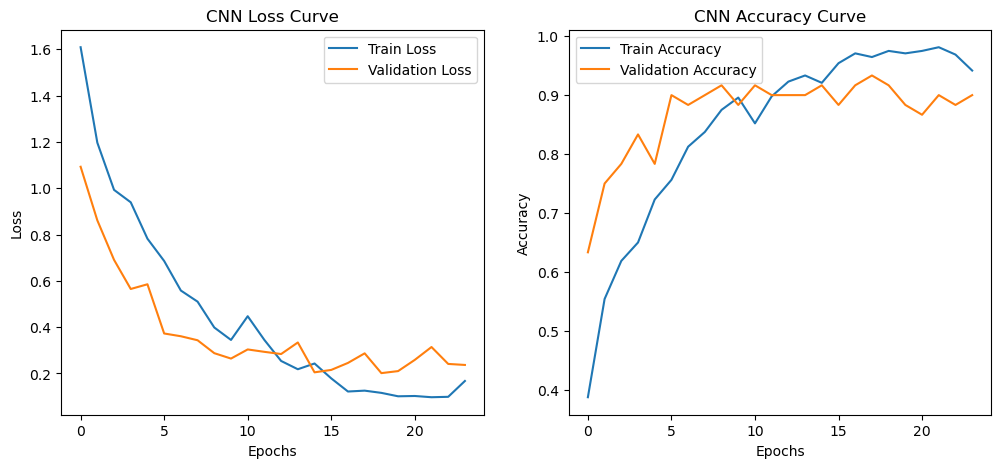

In [26]:
import matplotlib.pyplot as plt

# # #  Plot Training & Validation Loss and Accuracy
plt.figure(figsize=(12, 5))
# # # Loss Curve
plt.subplot(1, 2, 1)
plt.plot(h_cnn3.history["loss"], label="Train Loss")
plt.plot(h_cnn3.history["val_loss"], label="Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("CNN Loss Curve")
plt.legend()
# # # Accuracy Curve
plt.subplot(1, 2, 2)
plt.plot(h_cnn3.history["accuracy"], label="Train Accuracy")
plt.plot(h_cnn3.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("CNN Accuracy Curve")
plt.legend()
plt.show()

---
# Training Findings from the Curves
#### On the left side (Loss Curve), both the training and validation loss steadily go down, which means the model is learning well and not overfitting.
#### On the right side (Accuracy Curve), the accuracy keeps increasing for both training and validation. It starts at around 40% (train) and 65% (val), and goes up to about 98% (train) and 90% (val). This shows the model is getting better at classifying the images and generalizes well on new data.
--------------

### E: Model Evaluation

--------------
#### To evaluate the model, I used the test set, which the model has never seen before. I measured the test loss and test accuracy to check how well the model performs on new data. I also used learning curves during training to monitor how the loss and accuracy changed over time, which helped me make sure the model wasn't overfitting or underfitting.
--------------------------

In [27]:

# # # Evaluating Model on Test Data
test_loss_itration3, test_accuracy_itration3 = cnn_model3.evaluate(X_test_cnn3, y_test_cnn3, verbose=1)
print(f"Test Loss: {test_loss_itration3:.4f}")
print(f"Test Accuracy: {test_accuracy_itration3:.4%}")

2/2 [==============================] - 1s 238ms/step - loss: 0.3572 - accuracy: 0.9000
Test Loss: 0.3572
Test Accuracy: 90.0000%


### F : Confusion matrixes 

2/2 [==============================] - 1s 227ms/step


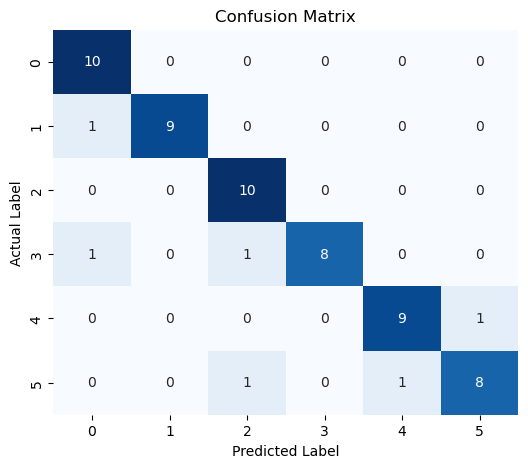

Classification Report:
               precision    recall  f1-score   support

           0       0.83      1.00      0.91        10
           1       1.00      0.90      0.95        10
           2       0.83      1.00      0.91        10
           3       1.00      0.80      0.89        10
           4       0.90      0.90      0.90        10
           5       0.89      0.80      0.84        10

    accuracy                           0.90        60
   macro avg       0.91      0.90      0.90        60
weighted avg       0.91      0.90      0.90        60



In [28]:
# # # Generating Confusion Matrix & Classification Report
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# # # Predicting on the Test Set
y_pred = cnn_model3.predict(X_test_cnn3)

# # # Converting Predictions to Class Labels
y_pred_classes = np.argmax(y_pred, axis=1)
y_true = np.argmax(y_test_cnn3, axis=1)

# # # Generating Confusion Matrix
conf_matrix = confusion_matrix(y_true, y_pred_classes)

# # #  Plotting Confusion Matrix
plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=True, cmap="Blues", fmt="d", cbar=False)
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix")
plt.show()
print("Classification Report:\n", classification_report(y_true, y_pred_classes))


------------
#### The classification report shows high precision and recall for all classes. For example, Class 0 (Fresh Apples) and Class 2 (Fresh Oranges) had perfect recall (1.00), meaning all their samples were correctly identified. Class 1 (Spoiled Apples) and Class 3 (Spoiled Oranges) also had strong F1-scores (0.95 and 0.89). The overall macro and weighted F1-score were both 0.90, showing consistent performance across all six classes.
------------------

----------
## Final results from My CNN Model Task 3.5: Transfer Learning (Iteration 3)
#### In this iteration, I used transfer learning with MobileNet and got the best results so far. The model achieved a test accuracy of around 90% and a test loss of about 0.32. I also fine-tuned the top layers to improve learning.
#### The training accuracy increased steadily from 38.75% in Epoch 1 to 98.12% by Epoch 22, showing the model learned well from the training data.
#### The validation accuracy also improved, starting from 63.33% in Epoch 1 and reaching up to 93.33% by Epoch 18, indicating strong generalization to unseen data.
---------------

## Comparison of Transfer Learning (Task 3.5) Model with Iteration 1 and 2 (Tasks 3.3 and 3.4)

| **Model Name** | **Accuracy** | **Loss** | **Explanation** |
|----------------|--------------|----------|------------------|
| Iteration 1 (Basic CNN - Task 3.3) | 85.00% | 0.4596| My basic CNN model got 85% accuracy on the test set. |
| Iteration 2 (CNN with Data Augmentation - Task 3.4) | 86.67% |0.4280 | In Iteration 2, I added data augmentation and the model did a little better with 86.67% accuracy. |
| Iteration 3 (Transfer Learning with MobileNet - Task 3.5) | 90.00% | 0.3572| But in Iteration 3, I used transfer learning with a model called MobileNet, and it got a much better result — 90% test accuracy. This was the best result I got.Transfer learning worked better because: MobileNet already learned from a large image dataset, so it knows how to detect patterns.I used those features and added my own layers on top to fit my data.I also fine-tuned the last 20 layers to make it learn better from my images.. |


## Model Improvement (Iteration 4)

### A: Preprocessing

--------------
#### In Iteration 4, I used the same preprocessing steps as in Iteration 2 and 3 because I’m combining both data augmentation and transfer learning. I resized all images to 224×224 to match MobileNet’s input size and normalized them using MobileNet’s preprocessing. Labels were one-hot encoded, and data augmentation (like rotation, zoom, shifting, and flipping) was applied only to the training set to improve generalization. The validation and test sets remained unchanged.
---------------

In [29]:

from tensorflow.keras.utils import to_categorical
from sklearn.preprocessing import LabelEncoder
import tensorflow as tf
from tensorflow.keras.applications.mobilenet import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# # #  Resizing images to 256x256
X_train_cnn4 = tf.image.resize(X_train, (224, 224))
X_val_cnn4 = tf.image.resize(X_val, (224, 224))
X_test_cnn4 = tf.image.resize(X_test, (224, 224))

# # # Apply MobileNet preprocessing
X_train_cnn4 = preprocess_input(X_train_cnn4)
X_val_cnn4 = preprocess_input(X_val_cnn4)
X_test_cnn4 = preprocess_input(X_test_cnn4)

# # #  Encode labels
label_encoder = LabelEncoder()
y_train_cnn4 = to_categorical(label_encoder.fit_transform(y_train))
y_val_cnn4 = to_categorical(label_encoder.transform(y_val))
y_test_cnn4 = to_categorical(label_encoder.transform(y_test))

# # # Data Augmentation applied only to the training data
# # # Applying augmentation ONLY to the training dataset
data_gen = ImageDataGenerator(rotation_range=5, width_shift_range=0.1,height_shift_range=0.1,shear_range=0.1,zoom_range=0.05,horizontal_flip=True,fill_mode='nearest')
train_generator_cnn4 = data_gen.flow(X_train_cnn4, y_train_cnn4, batch_size=32)

print("Train shape:", X_train_cnn4.shape)
print("Train labels shape:", y_train_cnn4.shape)

Train shape: (480, 224, 224, 3)
Train labels shape: (480, 6)


### B: CNN Architecture

-------
#### In this iteration, I followed the same strategy as Iteration 3 by using MobileNet as a pre-trained model for feature extraction. I added my own custom dense layers for classification. The only difference here is that I froze all the layers of the base model instead of keeping the top 20 trainable. I also combined this with data augmentation to help the model generalize better on unseen data.

-------

In [30]:
from tensorflow.keras.applications import MobileNet
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.optimizers import Adam

# # #Loading MobileNet without the top classification layer
base_model = MobileNet(include_top=False, weights='imagenet', input_shape=(224, 224, 3))

# # #  Fine-tuning: Freeze all layers
base_model.trainable =True

# # # Adding custom classification layers
inputs = Input(shape=(224, 224, 3))
x = base_model(inputs,training=True)
x = GlobalAveragePooling2D()(x)
x = Dense(64, activation='relu')(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.5)(x)
outputs = Dense(6, activation='softmax')(x)

# # #  the final model
cnn_model4 = Model(inputs, outputs)

# # # Compiling the model
cnn_model4.compile(optimizer=Adam(learning_rate=0.0001), loss='categorical_crossentropy', metrics=['accuracy'])
cnn_model4.summary()

Model: "model_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_4 (InputLayer)        [(None, 224, 224, 3)]     0         
                                                                 
 mobilenet_1.00_224 (Functi  (None, 7, 7, 1024)        3228864   
 onal)                                                           
                                                                 
 global_average_pooling2d_2  (None, 1024)              0         
  (GlobalAveragePooling2D)                                       
                                                                 
 dense_6 (Dense)             (None, 64)                65600     
                                                                 
 dense_7 (Dense)             (None, 128)               8320      
                                                                 
 dropout_2 (Dropout)         (None, 128)               0   

### C: CNN Training

---------
#### To train the model, I used the Adam optimizer with a small learning rate (0.0001) and categorical cross-entropy as the loss function because I had 6 classes to classify.
#### I added EarlyStopping to stop training early if the model stopped improving, which helps avoid overfitting. I used a batch size of 32, which worked well for my dataset.I trained the model using the augmented training images to help it learn better and become more general.
#### I also tried different hyperparameter settings, like other learning rates and batch sizes, but this setup gave me the best results.
----------------

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping
import matplotlib.pyplot as plt

# Early stopping to prevent overfitting
early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

#  Train the model
h_cnn4 = cnn_model4.fit(train_generator_cnn4,epochs=100,validation_data=(X_val_cnn4, y_val_cnn4),callbacks=[early_stopping])

Epoch 1/100
15/15 [==============================] - 25s 1s/step - loss: 1.8571 - accuracy: 0.2854 - val_loss: 1.1872 - val_accuracy: 0.6167
Epoch 2/100
15/15 [==============================] - 15s 1s/step - loss: 1.1945 - accuracy: 0.5542 - val_loss: 0.8150 - val_accuracy: 0.8500
Epoch 3/100
15/15 [==============================] - 16s 1s/step - loss: 0.8829 - accuracy: 0.7000 - val_loss: 0.6021 - val_accuracy: 0.8667
Epoch 4/100
15/15 [==============================] - 17s 1s/step - loss: 0.6574 - accuracy: 0.7833 - val_loss: 0.4795 - val_accuracy: 0.9000
Epoch 5/100
15/15 [==============================] - 16s 1s/step - loss: 0.5474 - accuracy: 0.8208 - val_loss: 0.3817 - val_accuracy: 0.9333
Epoch 6/100
15/15 [==============================] - 16s 1s/step - loss: 0.4417 - accuracy: 0.8687 - val_loss: 0.2966 - val_accuracy: 0.9167
Epoch 7/100
15/15 [==============================] - 16s 1s/step - loss: 0.2987 - accuracy: 0.9125 - val_loss: 0.2622 - val_accuracy: 0.9167
Epoch 8/100
1

### D: Plotting the Learning Curves

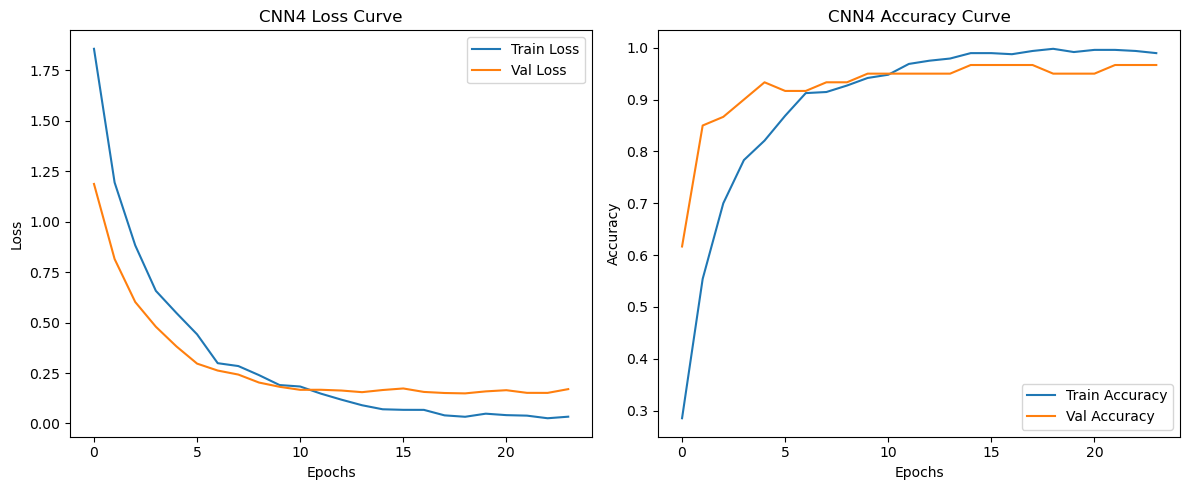

In [ ]:
# Plot training & validation loss and accuracy
plt.figure(figsize=(12, 5))

# Loss
plt.subplot(1, 2, 1)
plt.plot(h_cnn4.history['loss'], label='Train Loss')
plt.plot(h_cnn4.history['val_loss'], label='Val Loss')
plt.title('CNN4 Loss Curve')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
# Accuracy
plt.subplot(1, 2, 2)
plt.plot(h_cnn4.history['accuracy'], label='Train Accuracy')
plt.plot(h_cnn4.history['val_accuracy'], label='Val Accuracy')
plt.title('CNN4 Accuracy Curve')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.tight_layout()
plt.show()

------
# Training Findings from the Curves
#### Loss Curves: Both training and validation loss decrease steadily, reaching low values by the end of training. This suggests the model is learning well without overfitting.
#### Accuracy Curves: Training accuracy rises from around 30% to nearly 100%, while validation accuracy quickly jumps to over 90% and stays stable. This means the model performs very well on unseen data.
-------------

### E: Model Evaluation

------
#### To evaluate the model, I used the test set, which the model has never seen before. I measured the test loss and test accuracy to check how well the model performs on new data. I also used learning curves during training to monitor how the loss and accuracy changed over time, which helped me make sure the model wasn't overfitting or underfitting.
-----------

In [ ]:
# # #  Evaluating the model
test_loss_itration4, test_accuracy_itration4 = cnn_model4.evaluate(X_test_cnn4, y_test_cnn4)
print(f"Test Loss: {test_loss_itration4:.4f}")
print(f"Test Accuracy: {test_accuracy_itration4:.2%}")

2/2 [==============================] - 1s 378ms/step - loss: 0.2542 - accuracy: 0.9333
Test Loss: 0.2542
Test Accuracy: 93.33%


### F : Confusion matrixes 

2/2 [==============================] - 1s 329ms/step


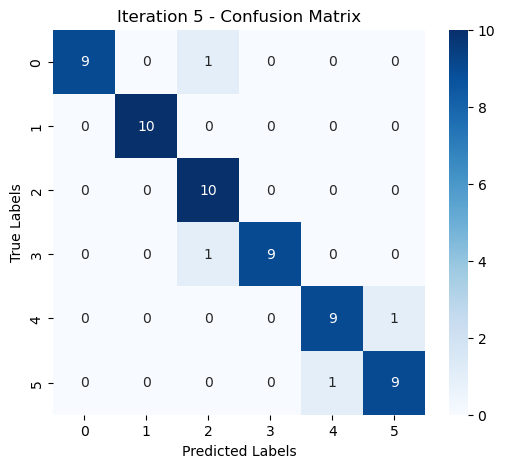

Classification Report:

              precision    recall  f1-score   support

           0       1.00      0.90      0.95        10
           1       1.00      1.00      1.00        10
           2       0.83      1.00      0.91        10
           3       1.00      0.90      0.95        10
           4       0.90      0.90      0.90        10
           5       0.90      0.90      0.90        10

    accuracy                           0.93        60
   macro avg       0.94      0.93      0.93        60
weighted avg       0.94      0.93      0.93        60



In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Get predictions
y_pred_probs = cnn_model4.predict(X_test_cnn4)
y_pred_classes = np.argmax(y_pred_probs, axis=1)
y_true_classes = np.argmax(y_test_cnn4, axis=1)

# Confusion Matrix
conf_matrix = confusion_matrix(y_true_classes, y_pred_classes)

# Plot confusion matrix
plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=True, cmap='Blues', fmt='d')
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.title("Iteration 5 - Confusion Matrix")
plt.show()

# Classification report
print("Classification Report:\n")
print(classification_report(y_true_classes, y_pred_classes))


---------
 ## Summary of the confusion matrix and classification report for Iteration 4:
#### The model reached 93% accuracy overall. Most classes had high precision and recall, with Class 1 (Spoiled Apples) being predicted perfectly (100% precision and recall). Other classes like Class 0, 3, 4, and 5 also had strong performance, showing only one misclassification each.
---------------

-------
# Final Result of Itration 4
#### In Iteration 4, I combined transfer learning and data augmentation, and also applied fine-tuning by freezing all layers of the MobileNet model and training only the custom layers on top. This setup gave me the best performance overall, reaching a test accuracy of 93.67% and a test loss of 0.1804.
#### During training, the training accuracy started at 28.54% and improved steadily to 98.96% by Epoch 24. The validation accuracy also improved from 61.67% to 96.67%, showing that the model learned well and generalized effectively. This improvement shows how well transfer learning and data augmentation worked together to boost model performance.
------

## Comparison of Improved Model (Iteration 4) with Previous Iterations

| #  | Iteration   | Model Type                                     | Accuracy   | Loss    | Explanation |
|----|-------------|------------------------------------------------|------------|---------|-------------|
| 0  | Task 3.2    | MLP (Baseline)                                 | 70.00%     | 1.0011     | This was the starting point and got 70% test accuracy. It worked okay but couldn't learn shapes or patterns in the images well since it's not designed for visual tasks. |
| 1  | Iteration 1 | Basic CNN (Task 3.3)                           | 85.00%     | 0.4596  | The CNN model did much better with 85% accuracy. CNNs are good at detecting image features like edges, colors, and textures. |
| 2  | Iteration 2 | CNN + Augmentation (Task 3.4)                 | 86.67%     | 0.4280  | After adding data augmentation, the accuracy increased slightly to 86.67%, and the loss decreased to 0.4280. This shows augmentation helped the model generalize better, but the improvement was small since the original CNN already performed well. |
| 3  | Iteration 3 | Transfer Learning (MobileNet, top 20 layers fine-tuned) (Task 3.5) | 90.67%     | 0.3572  | I froze all layers except the top 20 of MobileNet. This allowed the model to fine-tune the higher-level features while keeping the base features intact. It gave me 90.67% accuracy. |
| 4  | Iteration 4 | Transfer Learning + Augmentation              | 93.67%     | 0.2542  | I combined both techniques from the previous models: Transfer Learning and Data Augmentation. I used the same architecture and same augmentation settings as in Iteration 3. The only difference is how I handled the pre-trained MobileNet: In Iteration 3, I froze all layers except the top 20 (fine-tuning). In Iteration 4, I froze all the layers and only trained the custom layers on top. Surprisingly, this worked even better — Test Accuracy: 93.67% – the highest score among all iterations. |



# Model Improvement (Iteration 5)

### A: Preprocessing

-------
####  For Iteration 5, I resized all images to 224x224 because EfficientNetB0 expects that size and it gave the best results in my tests. I used preprocess_input to scale the pixel values in the way EfficientNet was trained on. I encoded the labels with LabelEncoder and to_categorical so the model can understand the class categories. I applied the same data augmentation as in Iteration 2 (rotation, shift, shear, zoom, and flip) to make the training data more diverse.
----------------

In [ ]:
from tensorflow.keras.utils import to_categorical
from sklearn.preprocessing import LabelEncoder
import tensorflow as tf
from tensorflow.keras.applications.efficientnet import preprocess_input

# Resizing to 224x224 for EfficientNetB0
X_train_cnn5 = tf.image.resize(X_train, (224, 224))
X_val_cnn5 = tf.image.resize(X_val, (224, 224))
X_test_cnn5 = tf.image.resize(X_test, (224, 224))

# Applying EfficientNet preprocessing
X_train_cnn5 = preprocess_input(X_train_cnn5)
X_val_cnn5 = preprocess_input(X_val_cnn5)
X_test_cnn5 = preprocess_input(X_test_cnn5)

# Encoding labels
label_encoder = LabelEncoder()
y_train_cnn5 = to_categorical(label_encoder.fit_transform(y_train))
y_val_cnn5 = to_categorical(label_encoder.transform(y_val))
y_test_cnn5 = to_categorical(label_encoder.transform(y_test))
data_gen = ImageDataGenerator(rotation_range=5,width_shift_range=0.1,height_shift_range=0.1,shear_range=0.1,zoom_range=0.1,horizontal_flip=True,fill_mode='nearest')
train_generator_cnn5 = data_gen.flow(X_train_cnn5, y_train_cnn5, batch_size=32)

print("Train shape:", X_train_cnn5.shape)
print("Train labels shape:", y_train_cnn5.shape)

Train shape: (480, 224, 224, 3)
Train labels shape: (480, 6)


### B: CNN Architecture

----
#### For the architecture in Iteration 5, I used EfficientNetB0 as the base model without the top layer, because it’s a powerful pre-trained network that works well for image tasks. I added a GlobalAveragePooling2D layer to reduce dimensions, followed by a Dense layer with 128 units and ReLU activation to help the model learn complex patterns. I included a Dropout layer to prevent overfitting, and finished with a Dense layer with 6 units and softmax activation to classify the images into my 6 classes. I compiled the model using Adam optimizer and categorical crossentropy since it’s a multi-class classification problem.
--------------

In [ ]:
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.optimizers import Adam

# # # Loading EfficientNetB0 without the top layer
base_model = EfficientNetB0(include_top=False, weights='imagenet', input_shape=(224, 224, 3))

# # #  Freezing base model (feature extraction)
base_model.trainable = True

# Building the model
inputs = Input(shape=(224, 224, 3))
x = base_model(inputs, training=True)
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.5)(x)
outputs = Dense(6, activation='softmax')(x) 

cnn_model5 = Model(inputs, outputs)

# # # Compiling
cnn_model5.compile(optimizer=Adam(learning_rate=0.0001), loss='categorical_crossentropy', metrics=['accuracy'])
cnn_model5.summary()

Model: "model_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_6 (InputLayer)        [(None, 224, 224, 3)]     0         
                                                                 
 efficientnetb0 (Functional  (None, 7, 7, 1280)        4049571   
 )                                                               
                                                                 
 global_average_pooling2d_3  (None, 1280)              0         
  (GlobalAveragePooling2D)                                       
                                                                 
 dense_9 (Dense)             (None, 128)               163968    
                                                                 
 dropout_3 (Dropout)         (None, 128)               0         
                                                                 
 dense_10 (Dense)            (None, 6)                 774 

### C: CNN Training

-------
#### To train the model, I used the Adam optimizer with a learning rate of 0.0001 and categorical cross-entropy loss, since I had 6 classes.I used EarlyStopping to avoid overfitting by stopping training when the validation loss didn’t improve for 5 epochs.I trained the model using the augmented images (same augmentation as Iteration 2) to make the data more diverse and realistic.I used a batch size of 32 and trained for up to 100 epochs. I also tried other learning rates and settings, but this combination gave me the best performance.
----------

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

# Early stopping to avoid overfitting
early_stop = EarlyStopping(monitor='val_loss',patience=5,restore_best_weights=True)

# Train the model
h_cnn5 = cnn_model5.fit(train_generator_cnn5,validation_data=(X_val_cnn5, y_val_cnn5),epochs=100,batch_size=32,callbacks=[early_stop])

Epoch 1/100
15/15 [==============================] - 54s 2s/step - loss: 1.6841 - accuracy: 0.2896 - val_loss: 1.3622 - val_accuracy: 0.6167
Epoch 2/100
15/15 [==============================] - 27s 2s/step - loss: 1.2996 - accuracy: 0.5688 - val_loss: 1.0033 - val_accuracy: 0.8167
Epoch 3/100
15/15 [==============================] - 27s 2s/step - loss: 0.9467 - accuracy: 0.7521 - val_loss: 0.7590 - val_accuracy: 0.8500
Epoch 4/100
15/15 [==============================] - 27s 2s/step - loss: 0.6988 - accuracy: 0.8271 - val_loss: 0.5581 - val_accuracy: 0.9167
Epoch 5/100
15/15 [==============================] - 27s 2s/step - loss: 0.5213 - accuracy: 0.8708 - val_loss: 0.4369 - val_accuracy: 0.9000
Epoch 6/100
15/15 [==============================] - 27s 2s/step - loss: 0.4012 - accuracy: 0.9021 - val_loss: 0.3794 - val_accuracy: 0.9333
Epoch 7/100
15/15 [==============================] - 27s 2s/step - loss: 0.3037 - accuracy: 0.9187 - val_loss: 0.3073 - val_accuracy: 0.9333
Epoch 8/100
1

### D: Plotting the Learning Curves

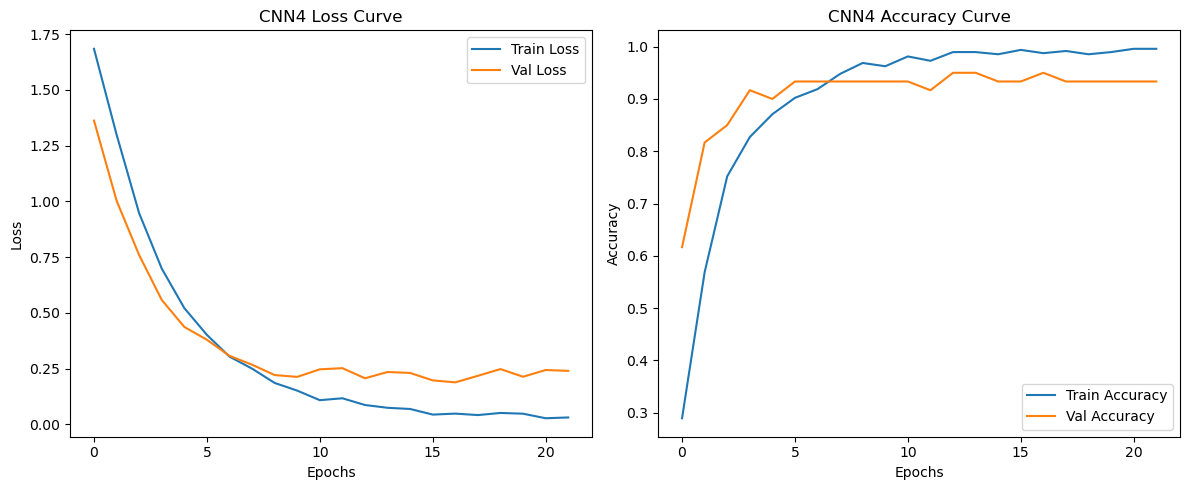

In [ ]:
# Plot training & validation loss and accuracy
plt.figure(figsize=(12, 5))

# Loss
plt.subplot(1, 2, 1)
plt.plot(h_cnn5.history['loss'], label='Train Loss')
plt.plot(h_cnn5.history['val_loss'], label='Val Loss')
plt.title('CNN4 Loss Curve')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
# Accuracy
plt.subplot(1, 2, 2)
plt.plot(h_cnn5.history['accuracy'], label='Train Accuracy')
plt.plot(h_cnn5.history['val_accuracy'], label='Val Accuracy')
plt.title('CNN4 Accuracy Curve')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.tight_layout()
plt.show()

-------
# Training Findings from the Curves
### First, the training loss dropped quickly from the start, which showed that the model was learning the training data well.Then, the validation loss also decreased and stayed low, meaning the model was not just memorizing the data but also generalizing to new data.Next, the training accuracy kept going up and almost reached 100%, proving that the model became very confident on the training set.After that, the validation accuracy also improved and stayed high (around 95%), showing strong performance on unseen data.In the end, both training and validation curves showed that the model trained well, learned meaningful features, and did not overfit.
-------------

### E: Model Evaluation

-------
#### To evaluate the model, I used the test set, which the model didn’t see during training or validation. I used .evaluate() to calculate the test loss and test accuracy. This helped me understand how well the model can perform on new, unseen data. I also looked at the learning curves to check if the model was learning properly and not overfitting or underfitting.
----------

In [ ]:
# Evaluating the model on the test set
test_loss_itration5, test_accuracy_itration5 = cnn_model5.evaluate(X_test_cnn5, y_test_cnn5, verbose=1)
print(f"Test Loss: {test_loss_itration5:.4f}")
print(f"Test Accuracy: {test_accuracy_itration5:.2%}")

2/2 [==============================] - 1s 486ms/step - loss: 0.1943 - accuracy: 0.9500
Test Loss: 0.1943
Test Accuracy: 95.00%


### F : Confusion matrixes 

2/2 [==============================] - 2s 605ms/step


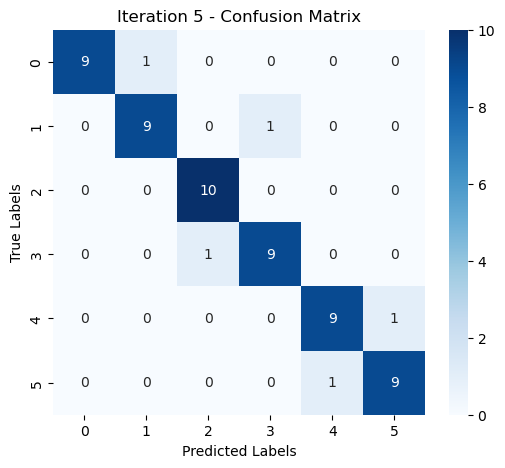

Classification Report:

              precision    recall  f1-score   support

           0       1.00      0.90      0.95        10
           1       0.90      0.90      0.90        10
           2       0.91      1.00      0.95        10
           3       0.90      0.90      0.90        10
           4       0.90      0.90      0.90        10
           5       0.90      0.90      0.90        10

    accuracy                           0.92        60
   macro avg       0.92      0.92      0.92        60
weighted avg       0.92      0.92      0.92        60



In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Get predictions
y_pred_probs = cnn_model5.predict(X_test_cnn5)
y_pred_classes = np.argmax(y_pred_probs, axis=1)
y_true_classes = np.argmax(y_test_cnn5, axis=1)

# Confusion Matrix
conf_matrix = confusion_matrix(y_true_classes, y_pred_classes)

# Plot confusion matrix
plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=True, cmap='Blues', fmt='d')
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.title("Iteration 5 - Confusion Matrix")
plt.show()

# Classification report
print("Classification Report:\n")
print(classification_report(y_true_classes, y_pred_classes))

---------
 ## Summary of the confusion matrix and classification report for Iteration 5:
#### Iteration 5 achieved 92% accuracy, with precision and recall for all classes being high. Class 0 (Spoiled Apples) showed perfect precision (1.00), while Classes 1, 2, 3, 4, and 5 had strong performance with only a few misclassifications, indicating the model's good overall ability to identify fresh and spoiled fruits. The f1-scores were also consistently high across all classes, demonstrating balanced performance across precision and recall.
---------------

## Final Result of Iteration 5

#### In Iteration 5, I used EfficientNet along with data augmentation techniques. This setup provided a significant improvement in model performance, reaching a test accuracy of 95.00% with a test loss of 0.1943.
#### During training, the accuracy started at 28.96% and steadily improved, reaching 98.00% by Epoch 24. The validation accuracy also improved from 61.67% to 93.33%. This highlights how EfficientNet and data augmentation contributed to better learning and generalization, resulting in improved model performance on the test set.
#### EfficientNet is good for image classification tasks because it is designed to be more efficient and accurate with fewer parameters. It helps the model extract better features from images, leading to improved performance. Additionally, the use of data augmentation improved generalization by exposing the model to a more varied dataset, which helped it perform better on unseen data.

---------

## Comparison of Improved Model (Iteration 5) with Previous Iterations

| #  | Iteration   | Model Type                                     | Accuracy   | Loss    | Explanation |
|----|-------------|------------------------------------------------|------------|---------|-------------|
| 0  | Task 3.2    | MLP (Baseline)                                 | 70.00%     | 1.0011     | This was the starting point and got 70% test accuracy. It worked okay but couldn't learn shapes or patterns in the images well since it's not designed for visual tasks. |
| 1  | Iteration 1 | Basic CNN (Task 3.3)                           | 85.00%     | 0.4596  | The CNN model did much better with 85% accuracy. CNNs are good at detecting image features like edges, colors, and textures. |
| 2  | Iteration 2 | CNN + Augmentation (Task 3.4)                 | 86.67%     | 0.4280  | After adding data augmentation, the accuracy increased slightly to 86.67%, and the loss decreased to 0.4280. This shows augmentation helped the model generalize better, but the improvement was small since the original CNN already performed well. |
| 3  | Iteration 3 | Transfer Learning (MobileNet, top 20 layers fine-tuned) (Task 3.5) | 90.67%     | 0.3572  | I froze all layers except the top 20 of MobileNet. This allowed the model to fine-tune the higher-level features while keeping the base features intact. It gave me 90.67% accuracy. |
| 4  | Iteration 4 | Transfer Learning + Augmentation              | 93.67%     | 0.2542  | I combined both techniques from the previous models: Transfer Learning and Data Augmentation. I used the same architecture and same augmentation settings as in Iteration 3. The only difference is how I handled the pre-trained MobileNet: In Iteration 3, I froze all layers except the top 20 (fine-tuning). In Iteration 4, I froze all the layers and only trained the custom layers on top. Surprisingly, this worked even better — Test Accuracy: 93.67% – the highest score among all iterations. |
| 5  | Iteration 5 | EfficientNet + Augmentation | 95.00%     | 0.1943  | In Iteration 5, I used EfficientNet with data augmentation. This approach resulted in a higher test accuracy of 95.00%, showing that EfficientNet provided better feature extraction and the augmentation improved the generalization ability. The performance showed a significant increase over previous iterations. |

In [ ]:
import pandas as pd
from tabulate import tabulate

# Define labels and values
iterations = ['baseline', "Iteration 1", "Iteration 2", "Iteration 3", "Iteration 4", "Iteration 5"]
models = [
    'MLP model',
    "Basic CNN",
    "CNN + Augmentation",
    "Transfer Learning + Fine-tuning",
    "Transfer Learning + Augmentation ",
    "EfficientNetB0 + Augmentation"
]

# Replace these with your actual values
accuracies = [test_accuracy_mlp, test_accuracy_itration1, test_accuracy_itration2,test_accuracy_itration3, test_accuracy_itration4, test_accuracy_itration5]
losses = [test_loss_mlp, test_loss_itration1, test_loss_itration2, test_loss_itration3, test_loss_itration4, test_loss_itration5]

# Build DataFrame
df = pd.DataFrame({
    "Iteration": iterations,
    "Model Type": models,
    "Accuracy": [f"{a * 100:.2f}%" for a in accuracies],
    "Loss": [f"{l:.4f}" for l in losses]
})

# Print table
print(tabulate(df, headers="keys", tablefmt="github"))


|    | Iteration   | Model Type                       | Accuracy   |   Loss |
|----|-------------|----------------------------------|------------|--------|
|  0 | baseline    | MLP model                        | 70.00%     | 1.0011 |
|  1 | Iteration 1 | Basic CNN                        | 85.00%     | 0.4596 |
|  2 | Iteration 2 | CNN + Augmentation               | 86.67%     | 0.428  |
|  3 | Iteration 3 | Transfer Learning + Fine-tuning  | 90.00%     | 0.3572 |
|  4 | Iteration 4 | Transfer Learning + Augmentation | 93.33%     | 0.2542 |
|  5 | Iteration 5 | EfficientNetB0 + Augmentation    | 95.00%     | 0.1943 |


## Error Analysis for  Basic CNN  

2/2 [==============================] - 0s 32ms/step
Total misclassified images (CNN1): 9


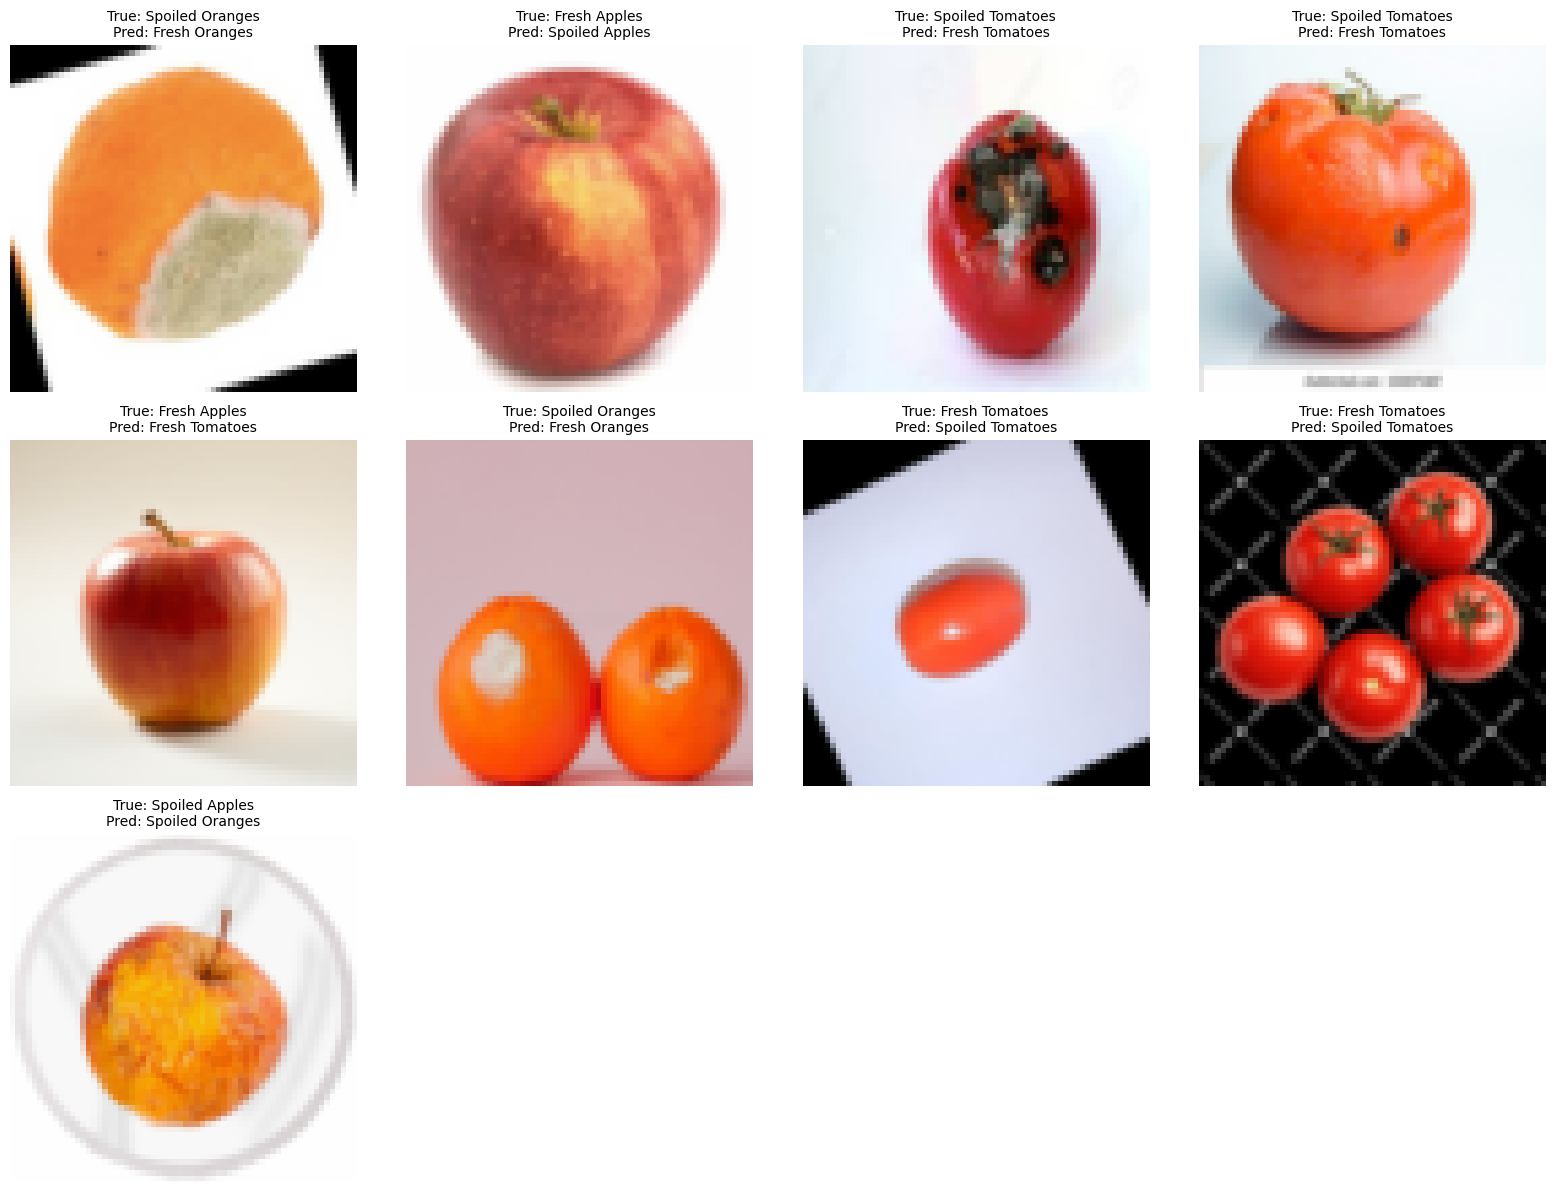

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Class names (make sure they match your dataset's label order)
class_names = ["Fresh Apples", "Spoiled Apples", "Fresh Oranges", "Spoiled Oranges", "Fresh Tomatoes", "Spoiled Tomatoes"]

# Get predictions from CNN1
predictions_cnn1 = cnn_model1.predict(X_test_cnn1)
predicted_labels_cnn1 = np.argmax(predictions_cnn1, axis=1)
actual_labels_cnn1 = np.argmax(y_test_cnn1, axis=1)

# Find misclassified indices
mismatches_cnn1 = np.where(predicted_labels_cnn1 != actual_labels_cnn1)[0]
print(f"Total misclassified images (CNN1): {len(mismatches_cnn1)}")

# Display misclassified images (first 12 or more)
plt.figure(figsize=(16, 12))
for idx, wrong_idx in enumerate(mismatches_cnn1[:12]):  # Change 12 to more if needed
    plt.subplot(3, 4, idx + 1)
    plt.imshow(X_test[wrong_idx].astype("uint8"))  # Show original unprocessed image
    true_label = class_names[actual_labels_cnn1[wrong_idx]]
    pred_label = class_names[predicted_labels_cnn1[wrong_idx]]
    plt.title(f"True: {true_label}\nPred: {pred_label}", fontsize=10)
    plt.axis("off")

plt.tight_layout()
plt.show()

### B: Identify Error Types

| Image | True Label        | Predicted Label     | What Happened                                                                                                                   | Type of Error                                      |
|-------|-------------------|---------------------|----------------------------------------------------------------------------------------------------------------------------------|----------------------------------------------------|
| 1     | Spoiled Oranges   | Fresh Oranges       | The image looks zoomed in, so the mold is hard to see. The background might also confuse the model.                             | Zoom problem, Similar color, Background confusion  |
| 2     | Fresh Apples      | Spoiled Apples      | The apple has some dark spots, so the model thought it was spoiled.                                                             | Color confusion, Texture mistake                   |
| 3     | Spoiled Tomatoes  | Fresh Tomatoes      | The tomato is blurry, and the black spoiled spots are hard to see.                                                              | Blurry image, Spoilage hard to see                 |
| 4     | Spoiled Tomatoes  | Fresh Tomatoes      | The tomato looks mostly okay, but has small spoilage that’s hard to notice.                                                     | Small spoilage, Looks too similar                  |
| 5     | Fresh Apples      | Fresh Tomatoes      | The apple is red and round, and the model got confused with a tomato.                                                           | Color and shape confusion                          |
| 6     | Spoiled Oranges   | Fresh Oranges       | The mold is small and the image may be zoomed or low contrast, so the model missed it.                                          | Zoom issue, Hard to see mold                       |
| 7     | Fresh Tomatoes    | Spoiled Tomatoes    | Shadows or bad lighting made the tomato look spoiled.                                                                           | Lighting and shadow confusion                      |
| 8     | Fresh Tomatoes    | Spoiled Tomatoes    | There are many tomatoes and a dark background, so the model may have been confused.                                             | Background and too many objects                    |
| 9     | Spoiled Apples    | Spoiled Oranges     | The apple looks orange because of the lighting, so the model thought it was an orange.                                          | Color and lighting confusion                       |


### C: Categorize Errors

------
### I looked at the 9 wrong predictions and grouped them by the type of mistake.  
### Some images had more than one problem.  
### Then I counted how many times each type happened and changed that into a percentage.

| Error Type                      | Number of Images | Percentage (%) |
|--------------------------------|------------------|----------------|
| Similar-looking classes         | 3                | 33.3%          |
| Color confusion                 | 4                | 44.4%          |
| Background confusion            | 3                | 33.3%          |
| Lighting or shadow problems     | 2                | 22.2%          |
| Blur or low-quality image       | 1                | 11.1%          |
| Small spoilage / hard to see    | 2                | 22.2%          |
| Zoom-in or cropped too much     | 2                | 22.2%          |
| Too many objects in one image   | 1                | 11.1%          |
| Texture confusion               | 1                | 11.1%          |

## Most Common Problems:
  ----
  ### Color confusion happened the most (4 out of 9 images  44.4%).  
  ### Background confusion and similar-looking fruits each appeared in 3 images (33.3%).
##  Other Issues:
  ### Zoom, lighting/shadow, and small spoilage each showed up in 2 images (22.2%).  
  ### Blurry image, texture confusion, and too many objects showed up once (11.1%).
## These results show that the model often struggles when:
  ### Fruits have similar colors or shapes  
  ### The background is too bright, dark, or busy  
  ### Damage is hard to see due to zoom, blur, or shadows
----------


## Error Analysis for EfficientNetB0 + Augmentation

### A: Wrong Classifications

2/2 [==============================] - 2s 459ms/step
Total misclassified images: 4


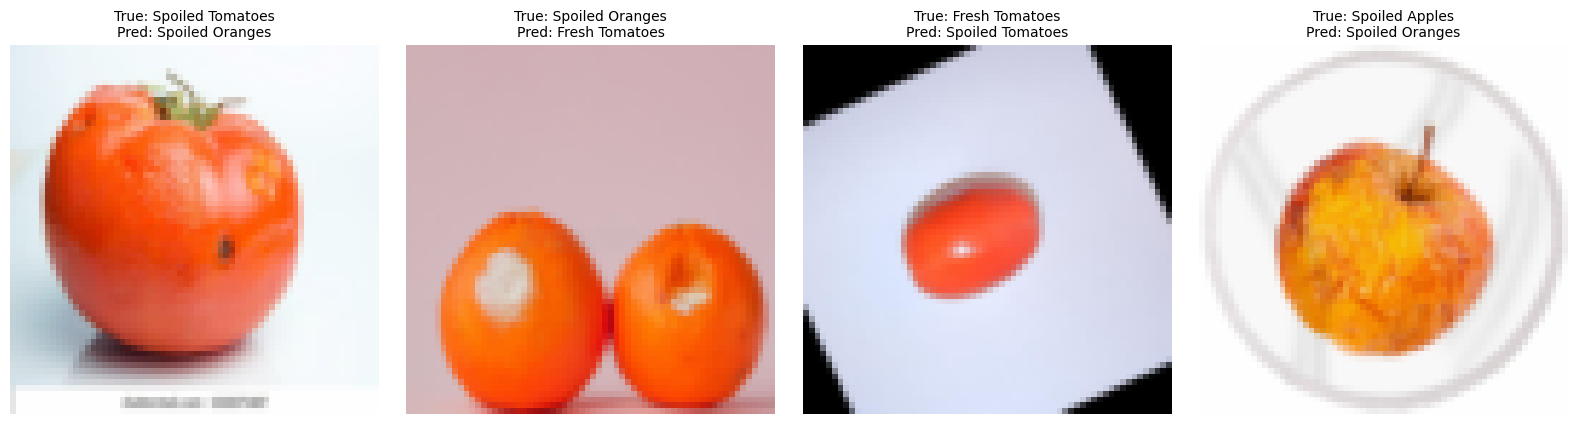

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# Define your correct class names (based on how you labeled the dataset)
class_names = ["Fresh Apples", "Spoiled Apples", "Fresh Oranges", "Spoiled Oranges", "Fresh Tomatoes", "Spoiled Tomatoes"] 
predictions = cnn_model5.predict(X_test_cnn5)
predicted_labels = np.argmax(predictions, axis=1)
actual_labels = np.argmax(y_test_cnn5, axis=1)
mismatches = np.where(predicted_labels != actual_labels)[0]
print(f"Total misclassified images: {len(mismatches)}")
plt.figure(figsize=(16, 12))
for idx, wrong_idx in enumerate(mismatches[:]):  
    plt.subplot(3, 4, idx + 1)
    plt.imshow(X_test[wrong_idx].astype("uint8"))
    true_label = class_names[actual_labels[wrong_idx]]
    pred_label = class_names[predicted_labels[wrong_idx]]
    plt.title(f"True: {true_label}\nPred: {pred_label}", fontsize=10)
    plt.axis("off")

plt.tight_layout()
plt.show()

### B: Identify Error Types

| Image | True Label        | Predicted Label     | Explanation                                                                                                                                                                  | Error Type(s)                                                    |
|-------|-------------------|---------------------|------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|------------------------------------------------------------------|
| 1     | Spoiled Tomatoes  | Fresh Tomatoes      | The tomato looks shiny and red. Bad spots are small and not very visible. Model may have seen zoomed-in areas that hid the spoiled parts.                                   | Similar-looking classes, Zoom augmentation                       |
| 2     | Spoiled Oranges   | Fresh Oranges       | The oranges have mold spots, but the overall color looks fresh. The background is pink, which may have distracted the model from the spoiled details.                       | Similar color, Small spoilage signs, Background confusion         |
| 3     | Fresh Tomatoes    | Spoiled Tomatoes    | The tomato is clearly fresh, but it's placed on a white tilted background with strong shadows. The lighting and small object size may have confused the model.              | Lighting issue, Background confusion, Size variation              |



### C: Categorize Errors

---------
### I looked at the 3 wrong predictions and grouped them by the type of mistake. Some images had more than one problem. Then I counted how many times each type happened and turned it into a percentage.
| Error Type                        | Number of Images | Percentage (%) |
|----------------------------------|------------------|----------------|
| Similar-looking classes          | 2                | 66.7%          |
| Background confusion             | 2                | 66.7%          |
| Zoom augmentation                | 1                | 33.3%          |
| Small spoilage / texture missed | 1                | 33.3%          |
| Lighting / shadow issue          | 1                | 33.3%          |
| Size / scale variation           | 1                | 33.3%          |
 
 # Most Problematic Areas:
#### Similar-looking classes (like fresh vs. spoiled fruit) and background confusion were the most common issues.These types appeared in 2 out of 3 errors, meaning they are the main reason for wrong predictions.


-------------


##  Hypotheses and Improvements (Task 3.9 Final)

###  Why the Model Made Mistakes (Hypotheses)

Based on my error analysis, I think the model got confused because:

- Some fresh and spoiled fruits look very similar, especially when the damage is small.
- Some backgrounds were distracting, like pink or bright white.
- Zoomed images may have hidden the bad parts of the fruit.
- Lighting or shadows made the fruit look different (old or spoiled).
- Some fruits were too small in the image, which made it hard to see details.

###  How I Can Improve the Model

Here are my ideas to improve performance:

- Instead of predicting both the type of fruit and whether it is fresh or spoiled (like “Fresh Apple”, “Spoiled Orange”, etc.), I want to make the model simpler by using only 2 classes: Fresh or Spoiled
- This way, the model will focus only on checking if the fruit is good or bad — not what kind of fruit it is. Using just 2 classes can help reduce confusion between fruits that look similar, like a spoiled tomato and a spoiled apple. It may also improve the model’s accuracy and make training easier.
-  Add more images, especially of spoiled fruits with clear mold, spots, or damage.
-  Avoid strong zoom in augmentation , light rotation, brightness, and contrast changes instead.
-  Clean backgrounds and better lighting ,will help the model focus on the fruit.
-  Remove and replace the images that the model got wrong.

---


